# Part 4 — The Fokker–Planck equation and its residual
Paper §3.1 (Eq. 8–14), App. A.2–A.3, Fig. 6. See [README.md](README.md).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent            # notebooks live one level below the project root
sys.path.insert(0, str(ROOT))
import numpy as np, torch, matplotlib.pyplot as plt
torch.set_default_dtype(torch.float64)      # float64: the FP estimator uses finite differences with sigma=1e-4
torch.set_num_threads(8)
from scoremd import sde, models, losses, sampling, simulate, metrics, potentials, plotting, experiments as ex
%matplotlib inline

## 1. Unit test: the exact diffused density satisfies Eq. 8
For the Gaussian mixture we know `log p_t` exactly, so the strong residual must be ~1e-15. This validates our
implementation of `F_p` (drift, divergence, signs, factors of ½).

In [2]:
x, info = ex.load_system('gmm')
truth = models.AnalyticModel(lambda a, b: info['gmm'].log_p_t(a, b, info['shift'], info['scale']))
for tv in [1e-3, 0.01, 0.1, 0.5, 0.9]:
    tt = torch.full((500,), tv); xt, _, _ = sde.perturb(x[:500], tt)
    print(f't={tv:6}:  mean |R(x,t)| = {losses.fp_residual_exact(truth, xt, tt).abs().mean():.2e}')

t= 0.001:  mean |R(x,t)| = 3.11e-16
t=  0.01:  mean |R(x,t)| = 7.88e-16
t=   0.1:  mean |R(x,t)| = 2.38e-15
t=   0.5:  mean |R(x,t)| = 2.23e-15
t=   0.9:  mean |R(x,t)| = 3.41e-15


## 2. The weak residual estimator is unbiased (Eq. 12, App. A.2)
One `v` gives a noisy estimate; averaging over many `v` converges to the exact (zero) residual.
`E[R̃(v) R̃(v')]` with independent `v, v'` is an unbiased estimate of the *squared* residual (Eq. 13).

E[R(v)^2]       (biased, = variance here): 77.62201685479057
E[R(v) R(v')]   (unbiased estimate of 0):   -0.24226072426244705


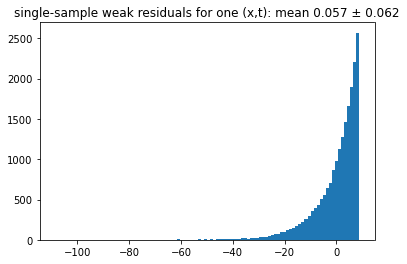

In [3]:
tv = 0.3; xs = x[:1]; tt = torch.full((1,), tv); xt, _, _ = sde.perturb(xs, tt)
K = 20_000
xr, tr = xt.repeat(K, 1), tt.repeat(K)
Rw = losses.fp_residual_weak(truth, xr, tr, 1e-4 * torch.randn_like(xr)).detach()
plt.hist(Rw.numpy(), 100); plt.title(f'single-sample weak residuals for one (x,t): mean {Rw.mean():.3f} ± {Rw.std() / K**0.5:.3f}')
r1, r2 = Rw[: K // 2], Rw[K // 2:]
print('E[R(v)^2]       (biased, = variance here):', float((Rw ** 2).mean()))
print("E[R(v) R(v')]   (unbiased estimate of 0):  ", float((r1 * r2).mean()))

## 3. Finite-difference time derivative (Eq. 14) vs. autograd

In [4]:
tt = torch.full((500,), 0.2); xt, _, _ = sde.perturb(x[:500], tt)
fd = losses.dt_log_p_fd(truth, xt, tt).detach(); ag = losses.dt_log_p_autograd(truth, xt, tt)
print('max |FD - autograd| =', float((fd - ag).abs().max()), '  typical |d/dt log p| =', float(ag.abs().mean()))

max |FD - autograd| = 0.0006101525275710173   typical |d/dt log p| = 5.501745514290125


## 4. FP error of the DSM-only model vs. diffusion time (Fig. 6)
We evaluate `‖R(x,t)‖` exactly (2D → cheap) on noised data for the DSM-only model from Part 1/3.
Expect: large near `t = 0`, smaller at larger `t`.

loaded gmm_diffusion_seed0.pt
loaded mb_diffusion_seed0.pt
exact density, RMS residual over all t: 4.028852879751257e-15


Text(0.5, 1.0, 'Fokker-Planck error (cf. Fig. 6)')

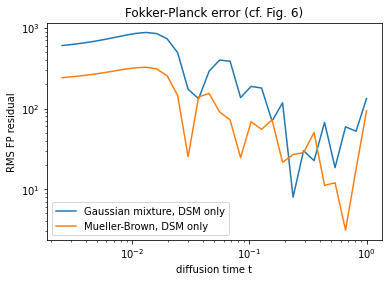

In [5]:
def fp_error_curve(model, x, ts, n=1000):
    out = []
    for tv in ts:
        tt = torch.full((n,), float(tv)); xt, _, _ = sde.perturb(x[:n], tt)
        out.append(float(losses.fp_residual_exact(model, xt, tt).pow(2).mean().sqrt()))
    return out
ts = torch.logspace(-2.6, 0, 30)   # t from ~0.0025 (FD needs t > h_s = 1e-3) to 1, log-spaced to resolve small t
gmm_model = ex.get_model('gmm_diffusion')
mb_x, _ = ex.load_system('mb'); mb_model = ex.get_model('mb_diffusion')
plt.semilogy(ts, fp_error_curve(gmm_model, x, ts), label='Gaussian mixture, DSM only')
plt.semilogy(ts, fp_error_curve(mb_model, mb_x, ts), label='Mueller-Brown, DSM only')
print('exact density, RMS residual over all t:', max(fp_error_curve(truth, x, ts[::6])))
plt.xscale('log'); plt.xlabel('diffusion time t'); plt.ylabel('RMS FP residual'); plt.legend(); plt.title('Fokker-Planck error (cf. Fig. 6)')

**Take-away.** DSM alone does not enforce Eq. 8, and the violation is concentrated at small `t` — exactly the
regime used for simulation. Part 5 adds `α·L_FP` to the loss.